# Telco customer churn: data preparation and exploration

The task is to predict whether a customer leaves the service. Churn is the
target: No = 0 and Yes = 1. The source describes churn within the last month.

This notebook inspects the original file, cleans its types and reserves a
test set. All feature analysis then uses training data. No model is fitted here.

Source: [Kaggle Telco Customer Churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn),
version 1, credited to IBM sample data. The CSV hash is checked by the loader.
Customer-level rows are kept local; saved outputs contain aggregates.

In [1]:
from pathlib import Path
import sys

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.data import load_data, clean_data, make_split, NUMERIC_FEATURES, CATEGORICAL_FEATURES, FEATURES

FIGURES = ROOT / "outputs/figures"
TABLES = ROOT / "outputs/tables"
FIGURES.mkdir(parents=True, exist_ok=True)
TABLES.mkdir(parents=True, exist_ok=True)
COLORS = ["#287C8E", "#C65E46"]
plt.rcParams.update({"font.size": 10, "figure.dpi": 110})

## 1. Inspect the original file

Read every column as text first so blank strings can be checked. The full-file
checks below cover structure and quality. They do not compare features against
the target. Distinct customers can have the same predictor values, so matching
predictor profiles alone are not a reason to delete a customer.

In [2]:
raw = load_data()
assert raw.shape == (7043, 21)
inspection = pd.Series({
    "rows": len(raw),
    "columns": len(raw.columns),
    "duplicate rows": raw.duplicated().sum(),
    "duplicate customer IDs": raw["customerID"].str.strip().duplicated().sum(),
    "repeated predictor profiles": raw.drop(columns=["customerID", "Churn"]).duplicated().sum(),
    "blank TotalCharges": raw["TotalCharges"].str.strip().eq("").sum(),
})
display(inspection.to_frame("count"))
inspection.to_csv(TABLES / "data_quality.csv", header=["count"])

,count
rows,7043
columns,21
duplicate rows,0
duplicate customer IDs,0
repeated predictor profiles,40
blank TotalCharges,11


## 2. Clean types and identify predictors

The helper trims whitespace, converts tenure and the charge fields to numbers,
and maps the target to 0/1. It rejects duplicate IDs, unknown target labels and
unexpected non-numeric values. SeniorCitizen remains a category despite its 0/1
labels. Customer IDs are retained for split checks and excluded from predictors.

All 11 blank TotalCharges values occur at zero tenure. Keep them as missing
because their actual values are unknown. Imputation will be fitted within
training folds during modelling. "No internet service" and "No phone service"
are valid service categories and stay unchanged. Charge units have not been
verified, so plots use source units.

In [3]:
data = clean_data(raw)
assert data.loc[data["TotalCharges"].isna(), "tenure"].eq(0).all()
assert data["TotalCharges"].isna().sum() == 11

column_summary = pd.DataFrame({
    "type": data.dtypes.astype(str),
    "missing": data.isna().sum(),
})
column_summary["role"] = "categorical predictor"
column_summary.loc[NUMERIC_FEATURES, "role"] = "numeric predictor"
column_summary.loc["customerID", "role"] = "identifier, excluded"
column_summary.loc["Churn", "role"] = "target, excluded from predictors"
display(column_summary)
column_summary.to_csv(TABLES / "columns.csv", index_label="column")
print("Numeric predictors:", NUMERIC_FEATURES)
print("Categorical predictors:", CATEGORICAL_FEATURES)

,type,missing,role
customerID,str,0,"identifier, excluded"
gender,str,0,categorical predictor
SeniorCitizen,str,0,categorical predictor
Partner,str,0,categorical predictor
Dependents,str,0,categorical predictor
tenure,int64,0,numeric predictor
PhoneService,str,0,categorical predictor
MultipleLines,str,0,categorical predictor
InternetService,str,0,categorical predictor
OnlineSecurity,str,0,categorical predictor


Numeric predictors: ['tenure', 'MonthlyCharges', 'TotalCharges']
Categorical predictors: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## 3. Reserve the test set

Use the existing 80/20 split with seed 42, stratified by Churn. Stratification
keeps similar class proportions in the two partitions. This reproduces the
original split, including row order. The tests check its membership against the
previously recorded hashes. Test features are reserved for final evaluation.

X_train contains 19 predictors; y_train contains only the target. No learned
imputation, scaling or encoding is performed here.

In [4]:
train, test = make_split(data)
assert len(train) == 5634 and len(test) == 1409
assert not (set(train["customerID"]) & set(test["customerID"]))
assert len(train) + len(test) == len(data)
X_train = train[FEATURES].copy()
y_train = train["Churn"].copy()
assert "customerID" not in X_train and "Churn" not in X_train
assert X_train["TotalCharges"].isna().sum() == 8
display(pd.DataFrame({
    "partition": ["training", "reserved test"],
    "rows": [len(train), len(test)],
}))
del test  # Further analysis uses training data only.

,partition,rows
0,training,5634
1,reserved test,1409


## 4. Training class balance

Churn is the positive class. Count both classes before comparing models;
accuracy alone can conceal missed churners in an imbalanced dataset.

,customers,percent
Churn,,
0,4139,73.46
1,1495,26.54


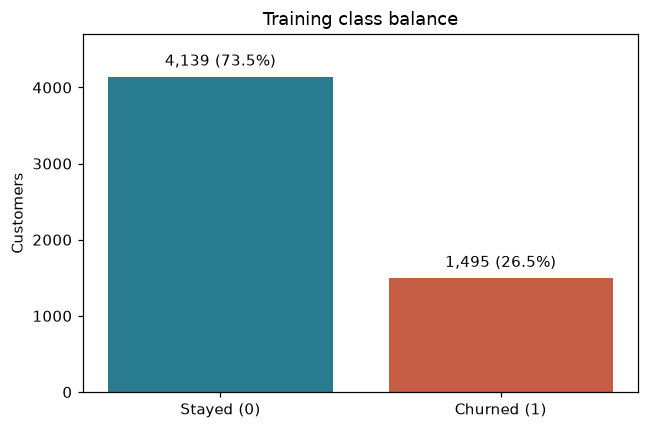

In [5]:
class_balance = y_train.value_counts().reindex([0, 1]).rename_axis("Churn").to_frame("customers")
class_balance["percent"] = class_balance["customers"] / len(train) * 100
display(class_balance.round(2))
class_balance.to_csv(TABLES / "class_balance.csv")

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["Stayed (0)", "Churned (1)"], class_balance["customers"], color=COLORS)
ax.bar_label(bars, labels=[f"{n:,} ({p:.1f}%)" for n, p in class_balance.itertuples(index=False)], padding=5)
ax.set(title="Training class balance", ylabel="Customers", ylim=(0, 4700))
fig.tight_layout()
fig.savefig(FIGURES / "class_balance.png", dpi=160)
plt.show()
plt.close(fig)

There are 1,495 churners among 5,634 training customers (26.54%). A classifier
that always predicts that a customer stays would achieve 73.46% training
accuracy while identifying no churners. Later evaluation should therefore
include churn precision, recall and F1 alongside accuracy.

## 5. Numeric distributions

Tenure measures months with the company. MonthlyCharges and TotalCharges are
the monthly and accumulated charges. The histograms compare each class using
density so the larger group does not dominate by size. Missing totals are
excluded from that variable's plot and summary, without filling them.

,count,mean,std,min,25%,50%,75%,max
tenure,5634.0,32.49,24.57,0.00,9.00,29.00,55.00,72.00
MonthlyCharges,5634.0,64.93,30.14,18.40,35.66,70.50,90.00,118.75
TotalCharges,5626.0,2302.60,2279.17,18.85,407.28,1398.12,3838.61,8684.80


,tenure,MonthlyCharges,TotalCharges
Churn,,,
0,38.0,64.40,1691.9
1,10.0,79.95,740.3


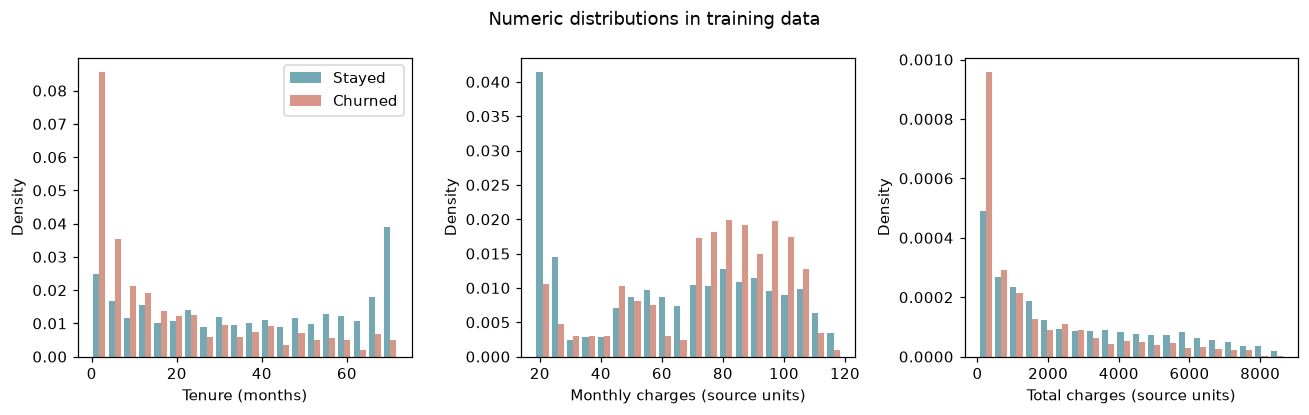

In [6]:
numeric_summary = X_train[NUMERIC_FEATURES].describe().T
display(numeric_summary.round(2))
numeric_summary.to_csv(TABLES / "numeric_summary.csv", index_label="feature")
medians = train.groupby("Churn")[NUMERIC_FEATURES].median()
display(medians.round(2))
medians.to_csv(TABLES / "numeric_medians_by_churn.csv")

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
labels = ["Tenure (months)", "Monthly charges (source units)", "Total charges (source units)"]
for ax, column, label in zip(axes, NUMERIC_FEATURES, labels):
    values = [train.loc[train["Churn"].eq(target), column].dropna() for target in [0, 1]]
    ax.hist(values, bins=20, density=True, color=COLORS, alpha=0.65, label=["Stayed", "Churned"])
    ax.set(xlabel=label, ylabel="Density")
axes[0].legend()
fig.suptitle("Numeric distributions in training data")
fig.tight_layout()
fig.savefig(FIGURES / "numeric_distributions.png", dpi=160)
plt.show()
plt.close(fig)

The median tenure is 10 months for churners and 38 months for customers who
stayed. Churners also have a higher median monthly charge: 79.95 compared with
64.40 source units. These are associations in the training sample; they do
not establish that a higher price or shorter tenure causes churn.

The predictors have different scales. Scaling will matter for KNN and logistic
regression. It must be fitted using training folds, together with imputation.

## 6. Churn rates by category

Compare contract, internet service, payment method and technical support. Each
bar shows the percentage of churners in that training group; n is its customer
count. Keep group sizes visible because rates from small groups are less stable.

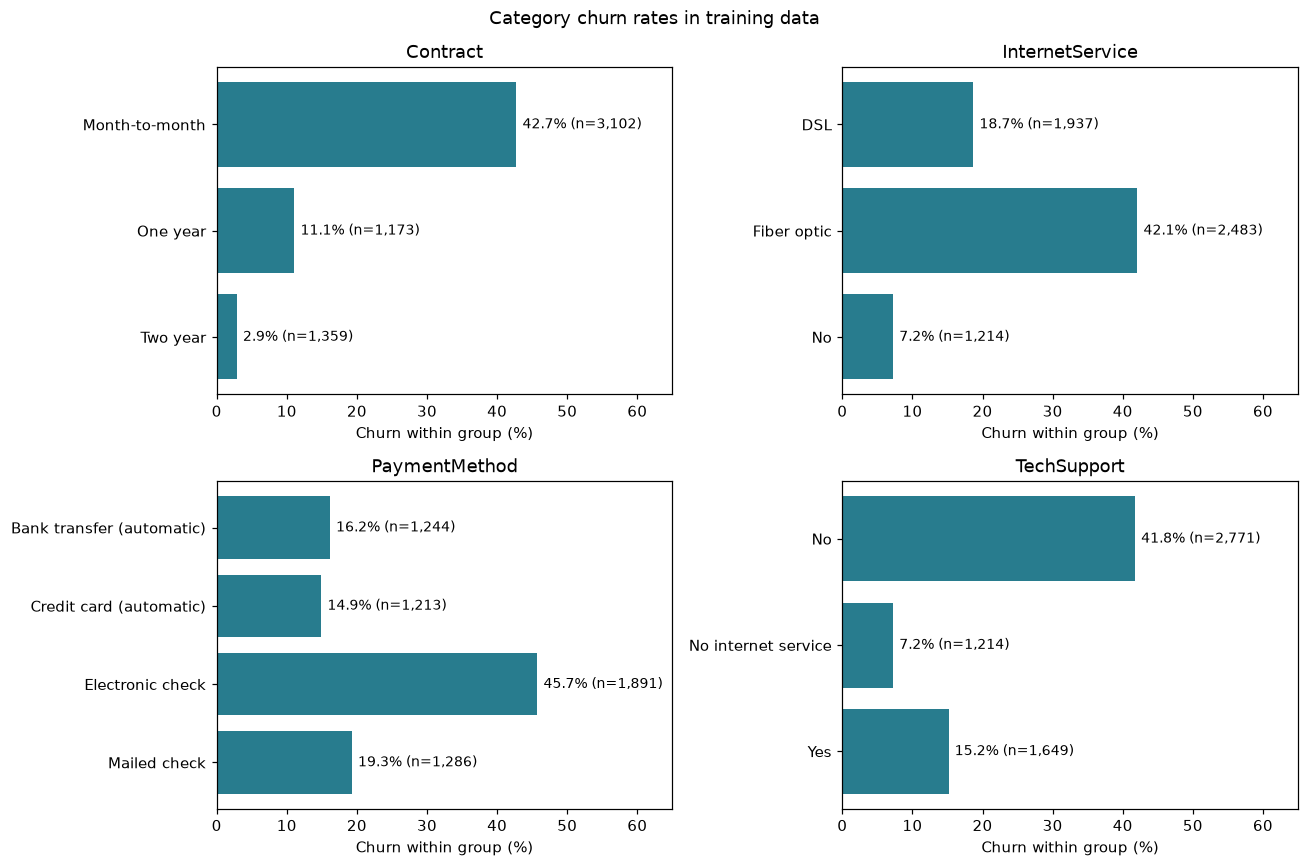

,feature,category,customers,churned,churn_percent
0,Contract,Month-to-month,3102,1326,42.75
1,Contract,One year,1173,130,11.08
2,Contract,Two year,1359,39,2.87
3,InternetService,DSL,1937,362,18.69
4,InternetService,Fiber optic,2483,1045,42.09
5,InternetService,No,1214,88,7.25
6,PaymentMethod,Bank transfer (automatic),1244,201,16.16
7,PaymentMethod,Credit card (automatic),1213,181,14.92
8,PaymentMethod,Electronic check,1891,865,45.74
9,PaymentMethod,Mailed check,1286,248,19.28


In [7]:
category_tables = []
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, column in zip(axes.flat, ["Contract", "InternetService", "PaymentMethod", "TechSupport"]):
    rates = train.groupby(column)["Churn"].agg(customers="size", churned="sum", churn_rate="mean")
    rates["churn_percent"] = rates.pop("churn_rate") * 100
    category_tables.append(rates.reset_index().rename(columns={column: "category"}).assign(feature=column))
    bars = ax.barh(rates.index, rates["churn_percent"], color=COLORS[0])
    ax.bar_label(bars, labels=[f"{p:.1f}% (n={n:,})" for n, p in zip(rates["customers"], rates["churn_percent"])], padding=4, fontsize=9)
    ax.set(title=column, xlabel="Churn within group (%)", xlim=(0, 65))
    ax.invert_yaxis()
fig.suptitle("Category churn rates in training data")
fig.tight_layout()
fig.savefig(FIGURES / "category_churn_rates.png", dpi=160)
plt.show()
plt.close(fig)

category_rates = pd.concat(category_tables, ignore_index=True)
category_rates = category_rates[["feature", "category", "customers", "churned", "churn_percent"]]
category_rates.to_csv(TABLES / "category_churn_rates.csv", index=False)
display(category_rates.round(2))

Month-to-month contracts have a 42.75% churn rate (3,102 customers), compared
with 11.08% for one-year contracts (1,173) and 2.87% for two-year contracts
(1,359). Contract type is worth retaining as a predictor. Other characteristics
can differ across these groups, so this comparison cannot show the effect of
changing a customer's contract.

## 7. Numeric relationships

Pearson correlation describes linear relationships between numeric predictors.
It does not measure every possible relationship. Missing values are omitted
pairwise in this table; all calculations use training data.

,tenure,MonthlyCharges,TotalCharges
tenure,1.000,0.257,0.829
MonthlyCharges,0.257,1.000,0.654
TotalCharges,0.829,0.654,1.000


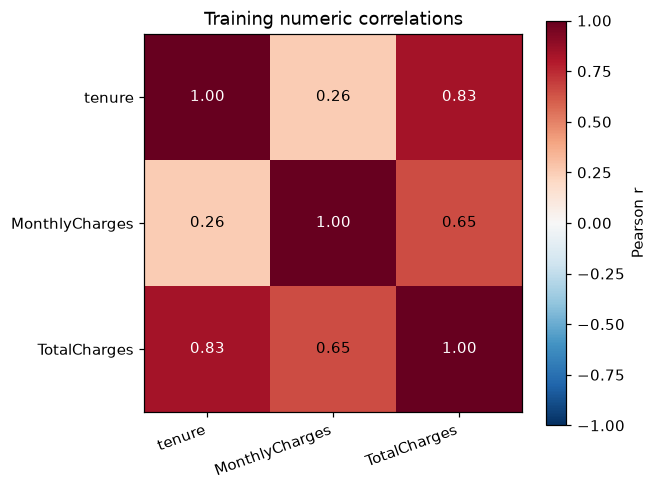

In [8]:
correlations = X_train[NUMERIC_FEATURES].corr()
display(correlations.round(3))
correlations.to_csv(TABLES / "numeric_correlations.csv", index_label="feature")
fig, ax = plt.subplots(figsize=(6, 4.8))
plot = ax.imshow(correlations, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(3), NUMERIC_FEATURES, rotation=20, ha="right")
ax.set_yticks(range(3), NUMERIC_FEATURES)
for row in range(3):
    for column in range(3):
        value = correlations.iloc[row, column]
        ax.text(column, row, f"{value:.2f}", ha="center", va="center", color="white" if abs(value) > 0.7 else "black")
ax.set_title("Training numeric correlations")
fig.colorbar(plot, ax=ax, label="Pearson r")
fig.tight_layout()
fig.savefig(FIGURES / "numeric_correlations.png", dpi=160)
plt.show()
plt.close(fig)

Tenure and TotalCharges have a correlation of about 0.83, consistent with
longer-standing customers accumulating more charges. Keep both for the initial
model comparison; correlation alone is insufficient reason to remove one.

## Decisions for the next phase

- Use 19 predictors and keep the customer ID and target separate.
- Fit numeric imputation, categorical encoding and any scaling inside training
  folds. Preserve service-absence categories.
- Compare KNN, logistic regression and random forest under the same validation
  conditions. Keep the test set reserved for the final chosen configuration.

These are sample data with limited evidence about how they represent a real
provider. No model performance or deployment suitability has been established.
Review the use of gender and SeniorCitizen, subgroup errors and privacy during
later evaluation. OpenAI Codex assisted with code and explanation drafts; the
student still needs to review the work and be able to explain every step.